In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8")


In [2]:
df = pd.read_csv("../data/cleaned_cafe_sales.csv", parse_dates=["transaction_date"])
df.head()


,transaction_id,item,quantity,price_per_unit,total_spent,payment_method,location,transaction_date,year,month,day_of_week
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08,2023,9,4
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16,2023,5,1
2,TXN_4271903,Cookie,4.0,1.0,4.0,Credit Card,In-store,2023-07-19,2023,7,2
3,TXN_7034554,Salad,2.0,5.0,10.0,Unknown,Unknown,2023-04-27,2023,4,3
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11,2023,6,6


In [3]:
df.describe()


,quantity,price_per_unit,total_spent,transaction_date,year,month,day_of_week
count,9540.000000,9540.000000,9540.000000,9540,9540.0,9540.000000,9540.000000
mean,3.024109,2.952673,8.935692,2023-07-01 23:00:31.698113536,2023.0,6.524004,3.014151
min,1.000000,1.000000,1.000000,2023-01-01 00:00:00,2023.0,1.000000,0.000000
25%,2.000000,2.000000,4.000000,2023-04-01 00:00:00,2023.0,4.000000,1.000000
50%,3.000000,3.000000,8.000000,2023-07-02 00:00:00,2023.0,7.000000,3.000000
75%,4.000000,4.000000,12.000000,2023-10-02 00:00:00,2023.0,10.000000,5.000000
max,5.000000,5.000000,25.000000,2023-12-31 00:00:00,2023.0,12.000000,6.000000
std,1.384186,1.243449,5.827677,NaN,0.0,3.449446,2.002752


In [4]:
total_revenue = df["total_spent"].sum()
total_revenue


np.float64(85246.5)

In [5]:
avg_ticket = df["total_spent"].mean()
avg_ticket


np.float64(8.93569182389937)

In [6]:
item_sales = (
    df.groupby("item")["total_spent"]
      .sum()
      .sort_values(ascending=False)
)


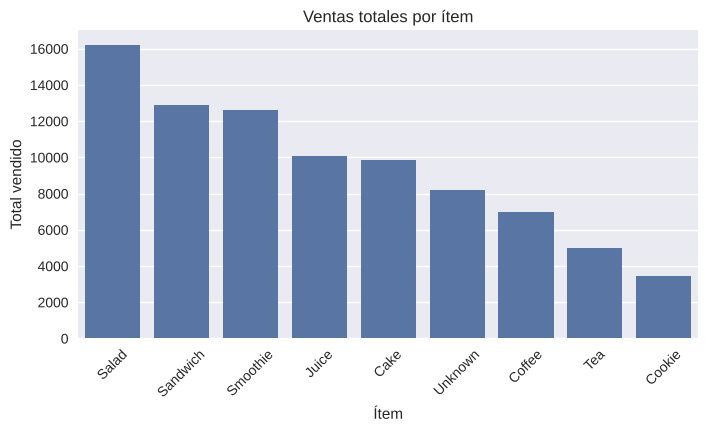

In [7]:
plt.figure(figsize=(8,4))
sns.barplot(x=item_sales.index, y=item_sales.values)
plt.title("Ventas totales por ítem")
plt.ylabel("Total vendido")
plt.xlabel("Ítem")
plt.xticks(rotation=45)
plt.show()


In [8]:
qty_by_item = (
    df.groupby("item")["quantity"]
      .sum()
      .sort_values(ascending=False)
)


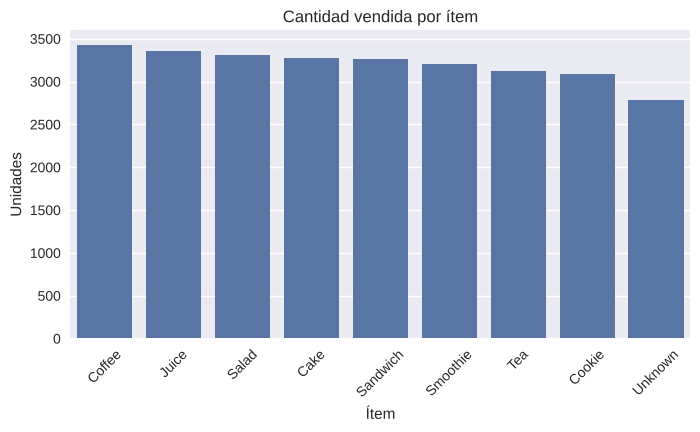

In [9]:
plt.figure(figsize=(8,4))
sns.barplot(x=qty_by_item.index, y=qty_by_item.values)
plt.title("Cantidad vendida por ítem")
plt.ylabel("Unidades")
plt.xlabel("Ítem")
plt.xticks(rotation=45)
plt.show()


In [10]:
monthly_sales = (
    df.groupby("month")["total_spent"]
      .sum()
)


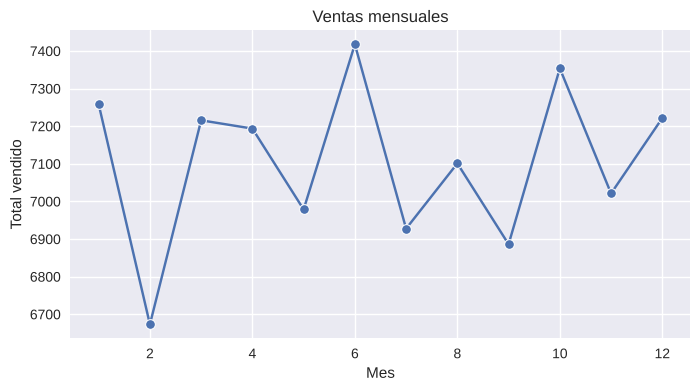

In [11]:
plt.figure(figsize=(8,4))
sns.lineplot(x=monthly_sales.index, y=monthly_sales.values, marker="o")
plt.title("Ventas mensuales")
plt.ylabel("Total vendido")
plt.xlabel("Mes")
plt.show()


In [12]:
payment_dist = df["payment_method"].value_counts(normalize=True) * 100
payment_dist


payment_method
Unknown           31.603774
Digital Wallet    23.029350
Credit Card       22.746331
Cash              22.620545
Name: proportion, dtype: float64

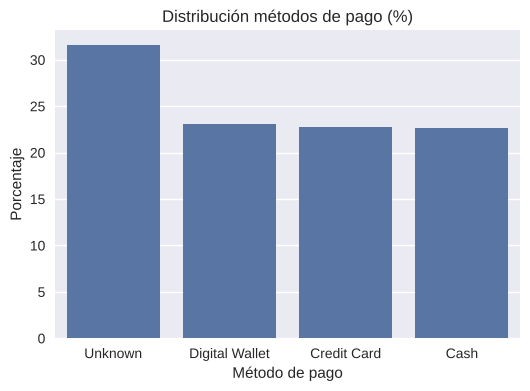

In [13]:
plt.figure(figsize=(6,4))
sns.barplot(x=payment_dist.index, y=payment_dist.values)
plt.title("Distribución métodos de pago (%)")
plt.ylabel("Porcentaje")
plt.xlabel("Método de pago")
plt.show()


In [14]:
location_sales = (
    df.groupby("location")["total_spent"]
      .sum()
)


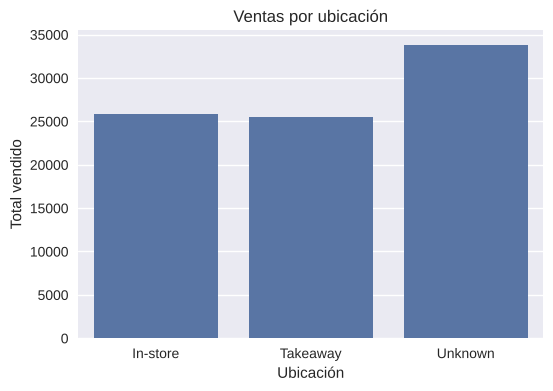

In [15]:
plt.figure(figsize=(6,4))
sns.barplot(x=location_sales.index, y=location_sales.values)
plt.title("Ventas por ubicación")
plt.ylabel("Total vendido")
plt.xlabel("Ubicación")
plt.show()


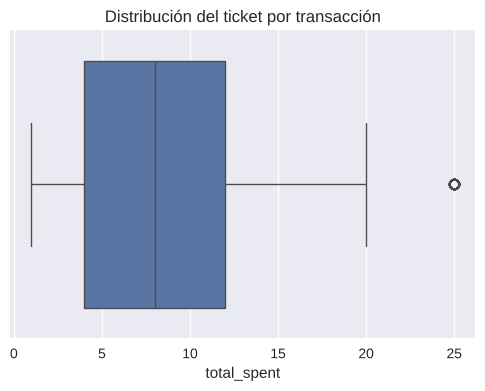

In [16]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df["total_spent"])
plt.title("Distribución del ticket por transacción")
plt.show()
